# 04 — Model Comparison

## Objective

In this notebook, we analyse and compare the performance of the machine learning models evaluated in Notebook 3.

We use the saved cross-validation results to:

1. Compare model performance across different evaluation metrics.
2. Visualize differences in classification performance.
3. Examine the consistency of model performance across the five folds.
4. Identify the strongest model configuration for further experimentation.

No models will be retrained in this notebook. We use the results saved in the previous notebook.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Loading Cross-Validation Results

We load two files generated in Notebook 3:

- `model_comparison_cv.csv`: Contains the mean and standard deviation of each evaluation metric for every model.
- `model_comparison_cv_folds.csv`: Contains the individual evaluation scores from each of the five folds.

These results allow us to compare both overall performance and consistency across folds.

In [10]:
# Load aggregate cross-validation results
comparison_df = pd.read_csv(
    "../results/metrics/model_comparison_cv.csv"
)

# Load individual fold results
fold_comparison_df = pd.read_csv(
    "../results/metrics/model_comparison_cv_folds.csv"
)

print("Overall comparison:")
display(comparison_df)

print("\nIndividual fold results:")
display(fold_comparison_df.head(10))

Overall comparison:


,Model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy Classifier,0.500247,0.000058,0.333443,0.000026,0.500000,0.000000,0.500000,0.000000
1,Logistic Regression (Unigrams),0.899344,0.003452,0.899323,0.003454,0.899337,0.003453,0.963559,0.001408
2,Logistic Regression (Unigrams + Bigrams),0.925575,0.002407,0.925543,0.002412,0.925565,0.002410,0.978464,0.000675
3,Linear SVM (Unigrams + Bigrams),0.943949,0.001281,0.943946,0.001281,0.943945,0.001281,0.986693,0.000330



Individual fold results:


,Model,Fold,accuracy,macro_f1,balanced_accuracy,roc_auc
0,Dummy Classifier,1,0.500155,0.333402,0.500000,0.500000
1,Dummy Classifier,2,0.500309,0.333471,0.500000,0.500000
2,Dummy Classifier,3,0.500309,0.333471,0.500000,0.500000
3,Dummy Classifier,4,0.500232,0.333436,0.500000,0.500000
4,Dummy Classifier,5,0.500232,0.333436,0.500000,0.500000
5,Logistic Regression (Unigrams),1,0.906124,0.906108,0.906120,0.966082
6,Logistic Regression (Unigrams),2,0.897618,0.897594,0.897609,0.963364
7,Logistic Regression (Unigrams),3,0.897154,0.897119,0.897143,0.963147
8,Logistic Regression (Unigrams),4,0.898840,0.898818,0.898833,0.961736
9,Logistic Regression (Unigrams),5,0.896984,0.896973,0.896979,0.963464


In [11]:
print("Number of models:", comparison_df["Model"].nunique())

print("\nNumber of folds per model:")
print(fold_comparison_df.groupby("Model")["Fold"].nunique())

print("\nMissing values in aggregate results:")
print(comparison_df.isnull().sum())

print("\nMissing values in fold results:")
print(fold_comparison_df.isnull().sum())

Number of models: 4

Number of folds per model:
Model
Dummy Classifier                            5
Linear SVM (Unigrams + Bigrams)             5
Logistic Regression (Unigrams + Bigrams)    5
Logistic Regression (Unigrams)              5
Name: Fold, dtype: int64

Missing values in aggregate results:
Model                     0
accuracy_mean             0
accuracy_std              0
macro_f1_mean             0
macro_f1_std              0
balanced_accuracy_mean    0
balanced_accuracy_std     0
roc_auc_mean              0
roc_auc_std               0
dtype: int64

Missing values in fold results:
Model                0
Fold                 0
accuracy             0
macro_f1             0
balanced_accuracy    0
roc_auc              0
dtype: int64


## 2. Comparing Model Performance

We compare the four models using accuracy, macro F1-score, balanced accuracy and ROC-AUC.

These metrics provide different perspectives on classification performance.

- Accuracy measures the overall proportion of correct predictions.
- Macro F1 measures the F1-score of each class equally and averages them.
- Balanced accuracy averages recall across both classes.
- ROC-AUC measures the ability of the model to distinguish between the two classes across different decision thresholds.

We use the mean cross-validation scores for this comparison.

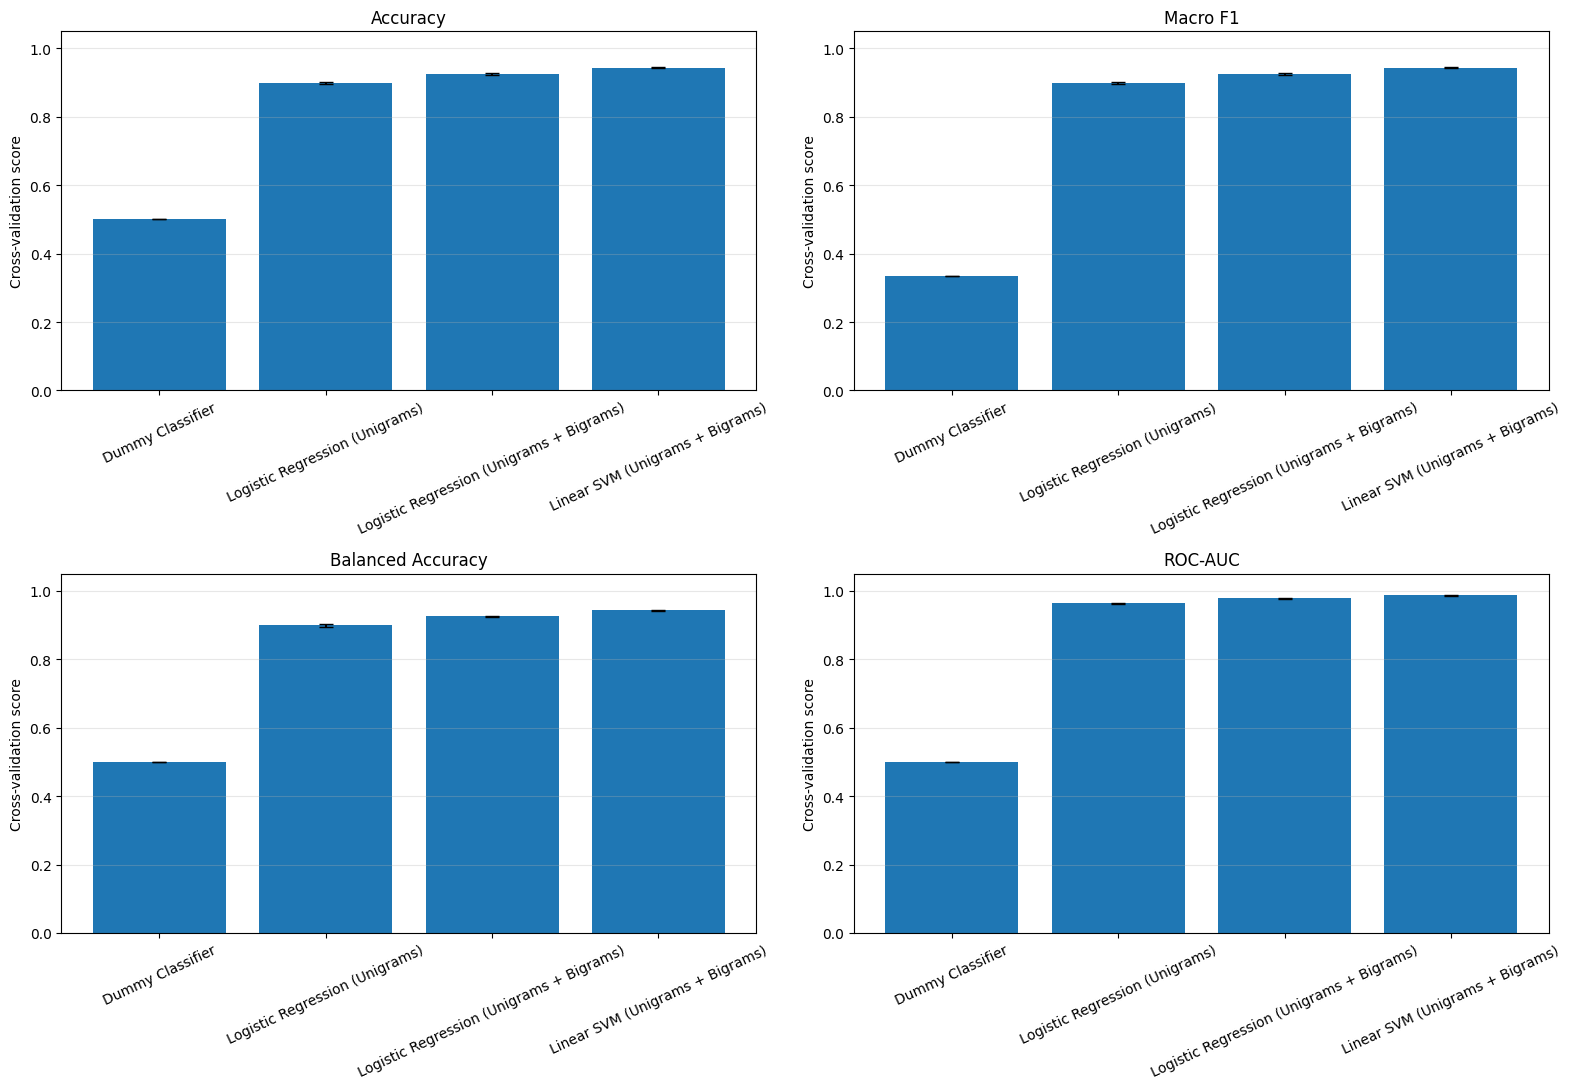

In [12]:
metrics = [
    ("accuracy_mean", "accuracy_std", "Accuracy"),
    ("macro_f1_mean", "macro_f1_std", "Macro F1"),
    ("balanced_accuracy_mean", "balanced_accuracy_std", "Balanced Accuracy"),
    ("roc_auc_mean", "roc_auc_std", "ROC-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, (mean_col, std_col, title) in zip(axes.flatten(), metrics):

    ax.bar(
        comparison_df["Model"],
        comparison_df[mean_col],
        yerr=comparison_df[std_col],
        capsize=5
    )

    ax.set_title(title)
    ax.set_ylabel("Cross-validation score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../results/figures/cv_score_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 3. Model Consistency Across Cross-Validation Folds

Mean cross-validation scores provide an overall estimate of model performance, but they do not show how performance varies across individual folds.

We use boxplots to visualize the distribution of evaluation scores across the five folds.

This helps us investigate whether a model performs consistently across different subsets of the training data.

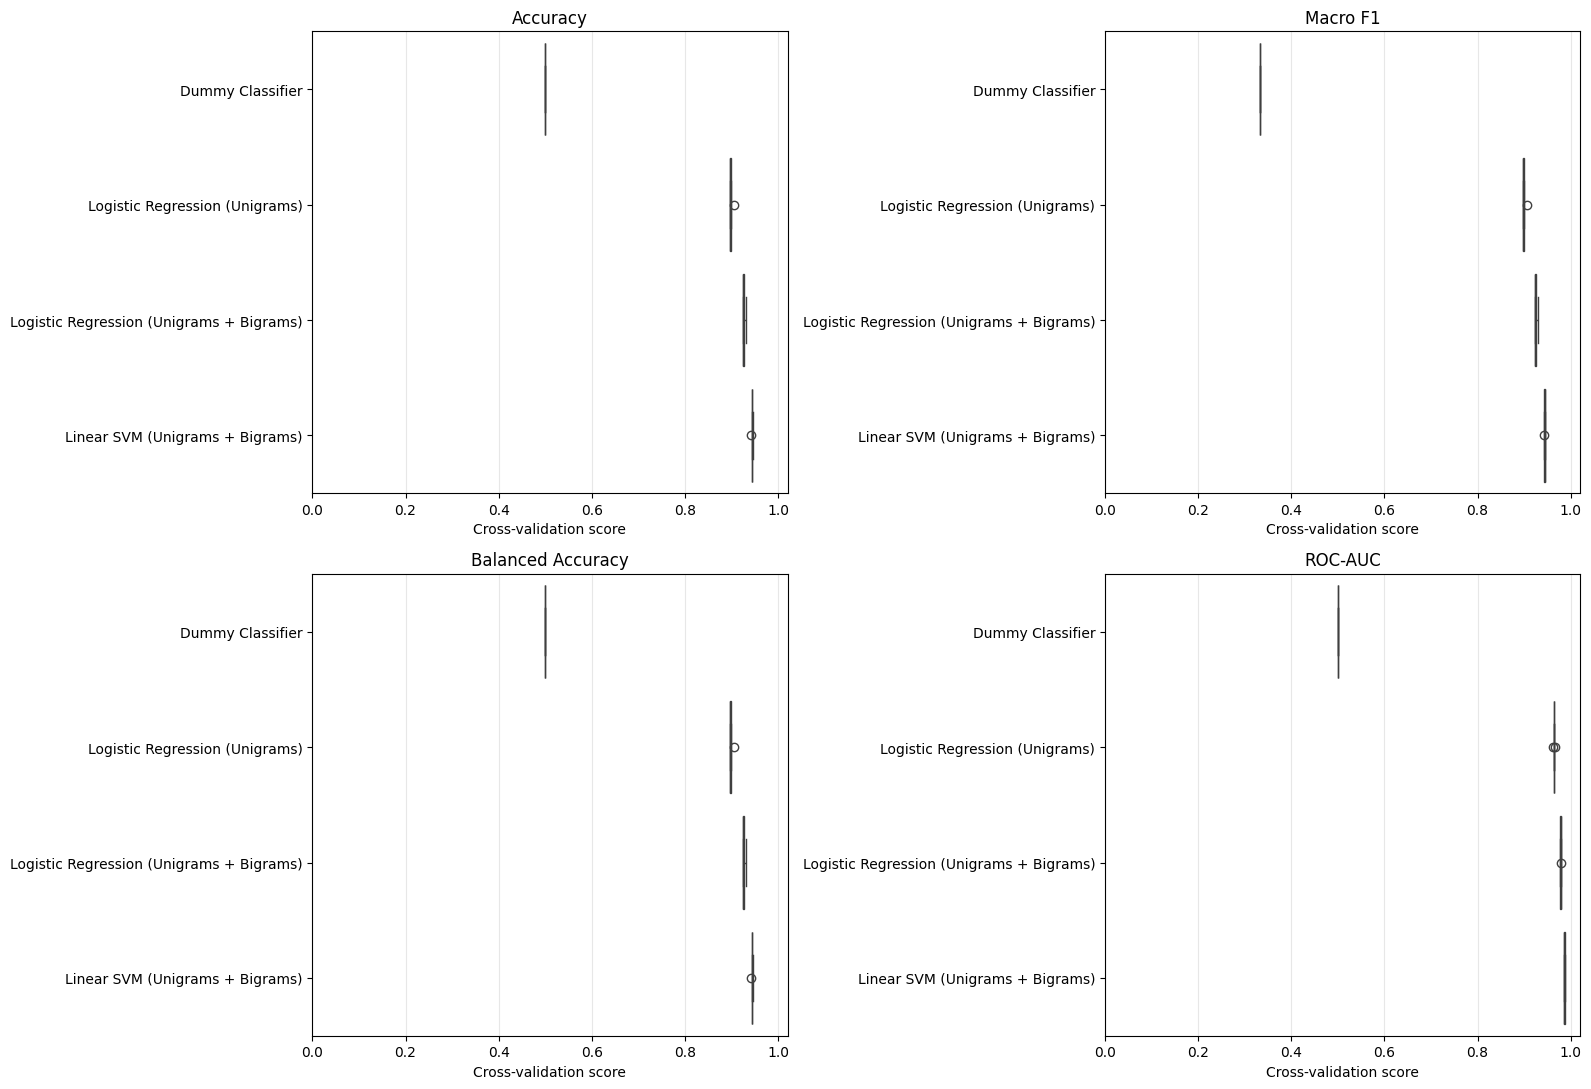

In [13]:
metrics_to_plot = [
    ("accuracy", "Accuracy"),
    ("macro_f1", "Macro F1"),
    ("balanced_accuracy", "Balanced Accuracy"),
    ("roc_auc", "ROC-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

model_order = comparison_df["Model"].tolist()

for ax, (metric, title) in zip(axes.flatten(), metrics_to_plot):

    sns.boxplot(
        data=fold_comparison_df,
        x=metric,
        y="Model",
        order=model_order,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Cross-validation score")
    ax.set_ylabel("")
    ax.set_xlim(0, 1.02)
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/fold_consistency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Performance Improvements Between Models

We now quantify the improvements obtained by changing the feature representation and classification algorithm.

We investigate:

1. The effect of adding bigram features to Logistic Regression.
2. The effect of replacing Logistic Regression with Linear SVM while retaining unigram and bigram features.

We calculate differences in mean cross-validation scores to quantify these improvements.

In [18]:
# Retrieve the results for each model
lr_uni = comparison_df[
    comparison_df["Model"] == "Logistic Regression (Unigrams)"
].iloc[0]

lr_bi = comparison_df[
    comparison_df["Model"] == "Logistic Regression (Unigrams + Bigrams)"
].iloc[0]

svm_bi = comparison_df[
    comparison_df["Model"] == "Linear SVM (Unigrams + Bigrams)"
].iloc[0]

# Calculate improvements
improvements = []

comparisons = [
    ("Adding bigrams to Logistic Regression", lr_uni, lr_bi),
    ("Replacing Logistic Regression with Linear SVM", lr_bi, svm_bi)
]

metrics_to_compare = [
    "accuracy",
    "macro_f1",
    "balanced_accuracy",
    "roc_auc"
]

for comparison_name, baseline, improved in comparisons:

    row = {"Comparison": comparison_name}

    for metric in metrics_to_compare:

        difference = (
            improved[f"{metric}_mean"]
            - baseline[f"{metric}_mean"]
        )

        row[metric] = difference

    improvements.append(row)

improvement_df = pd.DataFrame(improvements)

improvement_df

,Comparison,accuracy,macro_f1,balanced_accuracy,roc_auc
0,Adding bigrams to Logistic Regression,0.026231,0.026221,0.026228,0.014906
1,Replacing Logistic Regression with Linear SVM,0.018374,0.018402,0.018380,0.008229


### Interpretation of Performance Improvements

Adding bigram features to Logistic Regression improves accuracy by approximately 2.62 percentage points and macro F1 by 2.62 percentage points. This indicates that consecutive word combinations provide additional useful information beyond individual words.

Replacing Logistic Regression with Linear SVM, while keeping the same unigram and bigram TF-IDF representation, provides a further accuracy improvement of approximately 1.84 percentage points.

The improvements are consistent across accuracy, macro F1, balanced accuracy and ROC-AUC.

These results suggest that both feature representation and classifier choice influence performance. Linear SVM with unigram and bigram TF-IDF is therefore selected as the leading candidate for subsequent experiments.

## 5. Selecting the Leading Model

Based on the initial cross-validation experiments, Linear SVM with unigram and bigram TF-IDF achieves the strongest mean performance across the four evaluation metrics.

Its performance is also consistent across the five folds.

Therefore, it is selected as the leading candidate for further feature experiments.

This is a provisional selection. The next notebook will investigate whether alternative TF-IDF configurations can improve performance.

In [15]:
# Rank models by macro F1 score
ranked_models = comparison_df.sort_values(
    by="macro_f1_mean",
    ascending=False
).reset_index(drop=True)

ranked_models[
    ["Model", "accuracy_mean", "macro_f1_mean",
     "balanced_accuracy_mean", "roc_auc_mean"]
]

,Model,accuracy_mean,macro_f1_mean,balanced_accuracy_mean,roc_auc_mean
0,Linear SVM (Unigrams + Bigrams),0.943949,0.943946,0.943945,0.986693
1,Logistic Regression (Unigrams + Bigrams),0.925575,0.925543,0.925565,0.978464
2,Logistic Regression (Unigrams),0.899344,0.899323,0.899337,0.963559
3,Dummy Classifier,0.500247,0.333443,0.500000,0.500000


## 6. Conclusion

The comparison of four model configurations using stratified 5-fold cross-validation shows that Linear SVM with unigram and bigram TF-IDF achieves the strongest overall performance.

The inclusion of bigram features improves Logistic Regression performance across all evaluation metrics. Replacing Logistic Regression with Linear SVM provides a further improvement while keeping the feature representation unchanged.

Linear SVM achieves a mean accuracy of approximately 94.39%, macro F1-score of 94.39%, balanced accuracy of 94.39% and ROC-AUC of 98.67%.

The small variation in performance across the five folds suggests that the model performs consistently across different training and validation subsets.

Therefore, Linear SVM with unigram and bigram TF-IDF is selected as the leading candidate for the next stage of experimentation.

Further experiments will investigate alternative TF-IDF configurations, including changes to vocabulary filtering and feature representation.

These results describe performance on this particular dataset and do not establish equivalent performance on reviews from unrelated sources.